<a href="https://colab.research.google.com/github/ssb60386-beep/AI-LAB/blob/main/LAB_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [72]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [73]:
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", data.target_names)

Dataset loaded successfully!
Features shape: (569, 30)
Target shape: (569,)
Target classes: ['malignant' 'benign']


In [74]:
print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

print("\nFirst five rows:")
print(X.head())

print("\nFirst five target values:")
print(y.head())


Input features:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target variable:
target

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1      

In [75]:
print("Missing values in each column:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())

print("\nTarget class distribution:")
print(y.value_counts().rename(index={
    0: "Malignant",
    1: "Benign"
}))

Missing values in each column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

Total missing values: 0

Target class distribution:
target
Benign       357
Malignant

In [76]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (455, 30)
Testing features: (114, 30)
Training labels: (455,)
Testing labels: (114,)


In [77]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [78]:
y_pred = model.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].to_numpy())

print("\nFirst 10 predicted values:")
print(y_pred[:10])

First 10 actual values:
[0 1 0 1 0 1 1 0 0 0]

First 10 predicted values:
[0 1 0 1 0 1 1 0 0 0]


In [79]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label=0
)

recall = recall_score(
    y_test, y_pred, pos_label=0
)

f1 = f1_score(
    y_test, y_pred, pos_label=0
)

print("Model Evaluation Results")
print("-------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Model Evaluation Results
-------------------------
Accuracy:  0.9825
Precision: 0.9762
Recall:    0.9762
F1-score:  0.9762


In [80]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

cm_df = pd.DataFrame(
    cm,
    index=["Actual Malignant", "Actual Benign"],
    columns=["Predicted Malignant", "Predicted Benign"]
)

print(cm_df)


                  Predicted Malignant  Predicted Benign
Actual Malignant                   41                 1
Actual Benign                       1                71


In [81]:
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Malignant", "Benign"],
    digits=4
))

              precision    recall  f1-score   support

   Malignant     0.9762    0.9762    0.9762        42
      Benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



In [82]:
results = pd.DataFrame({
    "Actual": y_test.map({
        0: "Malignant",
        1: "Benign"
    }),
    "Predicted": pd.Series(
        y_pred, index=y_test.index
    ).map({
        0: "Malignant",
        1: "Benign"
    })
})

print(results.head(15))

print("\nTotal test samples:", len(y_test))
print("Incorrect predictions:", (y_test != y_pred).sum())
print("Correct predictions:", (y_test == y_pred).sum())

        Actual  Predicted
256  Malignant  Malignant
428     Benign     Benign
501  Malignant  Malignant
363     Benign     Benign
564  Malignant  Malignant
464     Benign     Benign
358     Benign     Benign
343  Malignant  Malignant
516  Malignant  Malignant
567  Malignant  Malignant
292     Benign     Benign
199  Malignant  Malignant
527     Benign     Benign
121  Malignant  Malignant
353  Malignant  Malignant

Total test samples: 114
Incorrect predictions: 2
Correct predictions: 112


Logistic Regression Confusion Matrix:
[[41  1]
 [ 1 71]]


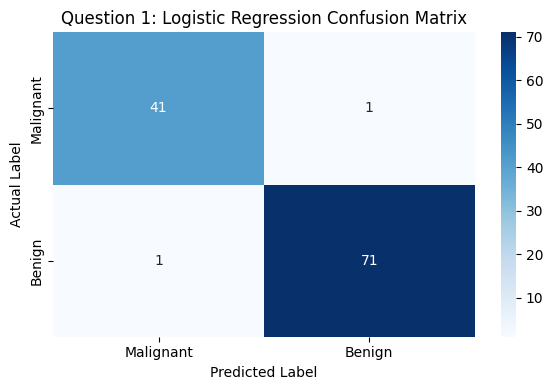

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Print confusion matrix
print("Logistic Regression Confusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Question 1: Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

 **Question No: 02**


In [84]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [85]:
iris = load_iris(as_frame=True)

# Input features and target variable
X = iris.data
y = iris.target

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Species:", iris.target_names)

print("\nFirst five rows:")
print(X.head())

print("\nFirst five target values:")
print(y.head())


Dataset loaded successfully!
Dataset shape: (150, 4)
Target shape: (150,)
Species: ['setosa' 'versicolor' 'virginica']

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

First five target values:
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [86]:
print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(iris.target_names)

# Convert numerical target labels into species names
print("\nSpecies distribution:")
print(y.map(dict(enumerate(iris.target_names))).value_counts())


Input features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target variable:
['setosa' 'versicolor' 'virginica']

Species distribution:
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [87]:
print("Dataset information:")
print(X.info())

print("\nSummary statistics:")
print(X.describe())

print("\nMissing values per feature:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())

print("\nDuplicate rows:", X.duplicated().sum())

print("\nClass distribution:")
print(y.value_counts().sort_index())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
None

Summary statistics:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
m

In [88]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training samples: 120
Testing samples: 30
Training feature shape: (120, 4)
Testing feature shape: (30, 4)


In [89]:
scaler = StandardScaler()

# Fit the scaler using training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to test data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)


Feature scaling completed!
Scaled training shape: (120, 4)
Scaled testing shape: (30, 4)


In [90]:
k_values = [3, 5, 7]

results = []

for k in k_values:
    # Create and train the KNN model
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    # Generate predictions
    y_pred = knn.predict(X_test_scaled)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "K": k,
        "Accuracy": accuracy,
        "Predictions": y_pred
    })

    print(f"\nResults for K = {k}")
    print("Accuracy:", round(accuracy, 4))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

# Compare model accuracies
comparison = pd.DataFrame([
    {"K": r["K"], "Accuracy": r["Accuracy"]}
    for r in results
])

print("\nModel Comparison:")
print(comparison.to_string(index=False))


Results for K = 3
Accuracy: 0.9333
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Results for K = 5
Accuracy: 0.9333
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Results for K = 7
Accuracy: 0.9667
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]

Model Comparison:
 K  Accuracy
 3  0.933333
 5  0.933333
 7  0.966667


In [91]:
k_values = [3, 5, 7]

results = []

for k in k_values:
    # Create and train the KNN model
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    # Generate predictions
    y_pred = knn.predict(X_test_scaled)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "K": k,
        "Accuracy": accuracy,
        "Predictions": y_pred
    })

    print(f"\nResults for K = {k}")
    print("Accuracy:", round(accuracy, 4))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

# Compare model accuracies
comparison = pd.DataFrame([
    {"K": r["K"], "Accuracy": r["Accuracy"]}
    for r in results
])

print("\nModel Comparison:")
print(comparison.to_string(index=False))


Results for K = 3
Accuracy: 0.9333
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Results for K = 5
Accuracy: 0.9333
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Results for K = 7
Accuracy: 0.9667
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]

Model Comparison:
 K  Accuracy
 3  0.933333
 5  0.933333
 7  0.966667


In [92]:
print("Comparison of KNN models")
print(comparison.to_string(index=False))

best_result = max(results, key=lambda r: r["Accuracy"])

print("\nBest K:", best_result["K"])
print("Best accuracy:", round(best_result["Accuracy"] * 100, 2), "%")

Comparison of KNN models
 K  Accuracy
 3  0.933333
 5  0.933333
 7  0.966667

Best K: 7
Best accuracy: 96.67 %


In [93]:
best_index = max(
    range(len(results)),
    key=lambda i: results[i]["Accuracy"]
)

best_result = results[best_index]
best_k = best_result["K"]
best_accuracy = best_result["Accuracy"]

print("Best K:", best_k)
print("Best test accuracy:", round(best_accuracy, 4))
print(f"Best test accuracy percentage: {best_accuracy * 100:.2f}%")

Best K: 7
Best test accuracy: 0.9667
Best test accuracy percentage: 96.67%


In [94]:
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_scaled, y_train)

best_predictions = best_knn.predict(X_test_scaled)

prediction_results = pd.DataFrame({
    "Actual Species": [
        iris.target_names[i] for i in y_test.to_numpy()
    ],
    "Predicted Species": [
        iris.target_names[i] for i in best_predictions
    ]
})

print(prediction_results.head(15))

print("\nCorrect predictions:",
      (y_test.to_numpy() == best_predictions).sum())

print("Incorrect predictions:",
      (y_test.to_numpy() != best_predictions).sum())

   Actual Species Predicted Species
0          setosa            setosa
1       virginica         virginica
2      versicolor        versicolor
3      versicolor        versicolor
4          setosa            setosa
5      versicolor        versicolor
6          setosa            setosa
7          setosa            setosa
8       virginica         virginica
9      versicolor        versicolor
10      virginica         virginica
11      virginica         virginica
12      virginica         virginica
13     versicolor        versicolor
14         setosa            setosa

Correct predictions: 29
Incorrect predictions: 1


In [95]:
print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1, 2],
    target_names=iris.target_names,
    digits=4
))

              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9091    1.0000    0.9524        10
   virginica     1.0000    0.9000    0.9474        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30




Confusion Matrix for K = 3:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Confusion Matrix for K = 5:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Confusion Matrix for K = 7:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


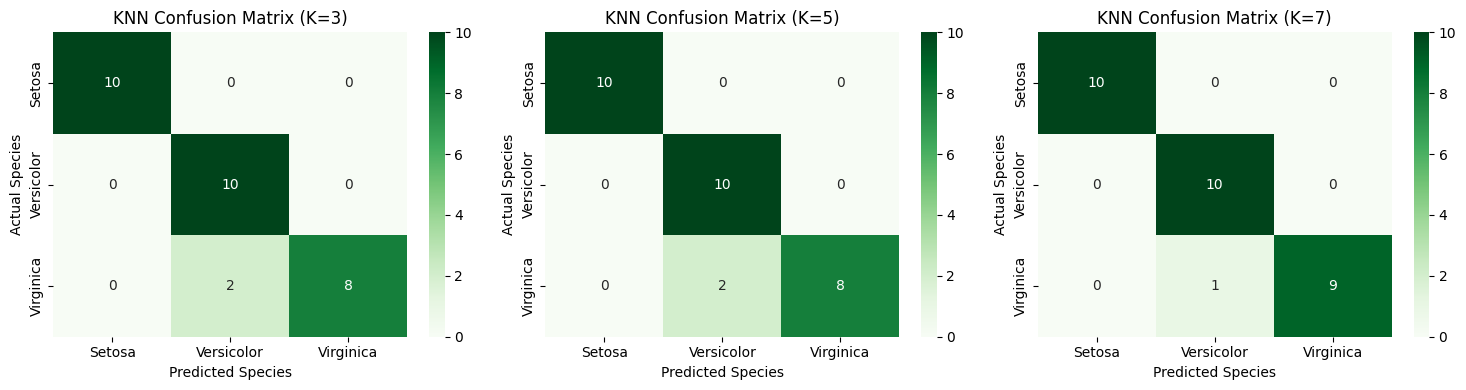

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

# Test different K values
k_values = [3, 5, 7]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, k in zip(axes, k_values):
    # Train KNN model
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    # Generate predictions
    y_pred_knn = knn.predict(X_test_scaled)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred_knn,
        labels=[0, 1, 2]
    )

    # Print confusion matrix
    print(f"\nConfusion Matrix for K = {k}:")
    print(cm)

    # Plot confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Greens",
        xticklabels=["Setosa", "Versicolor", "Virginica"],
        yticklabels=["Setosa", "Versicolor", "Virginica"],
        ax=ax
    )

    ax.set_title(f"KNN Confusion Matrix (K={k})")
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

**Question No: 03**


In [97]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


In [98]:
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", data.target_names)

print("\nFirst five rows:")
print(X.head())

Dataset loaded successfully!
Features shape: (569, 30)
Target shape: (569,)
Target classes: ['malignant' 'benign']

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980

In [99]:
print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

print("\nClass distribution:")
print(y.value_counts().rename(index={
    0: "Malignant",
    1: "Benign"
}))

print("\nMissing values:", X.isnull().sum().sum())


Input features:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target variable:
target

Class distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64

Missing values: 0


In [100]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [101]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf"))
])

# Train the SVM model
svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [102]:
y_pred_svm = svm_model.predict(X_test)

print("First 10 actual labels:")
print(y_test.iloc[:10].to_numpy())

print("\nFirst 10 predicted labels:")
print(y_pred_svm[:10])

print("\nClass labels: 0 = Malignant, 1 = Benign")

First 10 actual labels:
[0 1 0 1 0 1 1 0 0 0]

First 10 predicted labels:
[0 1 0 1 0 1 1 0 0 0]

Class labels: 0 = Malignant, 1 = Benign


In [103]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)

precision_svm = precision_score(
    y_test, y_pred_svm, pos_label=0
)

recall_svm = recall_score(
    y_test, y_pred_svm, pos_label=0
)

f1_svm = f1_score(
    y_test, y_pred_svm, pos_label=0
)

print("SVM Evaluation Results")
print("----------------------")
print(f"Accuracy:  {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall:    {recall_svm:.4f}")
print(f"F1-score:  {f1_svm:.4f}")

SVM Evaluation Results
----------------------
Accuracy:  0.9825
Precision: 0.9762
Recall:    0.9762
F1-score:  0.9762


In [104]:
cm_svm = confusion_matrix(
    y_test, y_pred_svm, labels=[0, 1]
)

print("Confusion Matrix:")
print(cm_svm)

Confusion Matrix:
[[41  1]
 [ 1 71]]


In [105]:
print(classification_report(
    y_test,
    y_pred_svm,
    labels=[0, 1],
    target_names=["Malignant", "Benign"],
    digits=4
))

              precision    recall  f1-score   support

   Malignant     0.9762    0.9762    0.9762        42
      Benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



In [106]:
# Train Logistic Regression on the same split
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# Evaluate Logistic Regression
accuracy_lr = accuracy_score(y_test, y_pred_lr)

precision_lr = precision_score(
    y_test, y_pred_lr, pos_label=0
)

recall_lr = recall_score(
    y_test, y_pred_lr, pos_label=0
)

f1_lr = f1_score(
    y_test, y_pred_lr, pos_label=0
)

# Create comparison table
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Logistic Regression": [
        accuracy_lr, precision_lr, recall_lr, f1_lr
    ],
    "SVM": [
        accuracy_svm, precision_svm, recall_svm, f1_svm
    ]
})

print(comparison.to_string(index=False, float_format="%.4f"))

# Identify the model with the higher test accuracy
if accuracy_svm > accuracy_lr:
    print("\nSVM has higher test accuracy.")
elif accuracy_lr > accuracy_svm:
    print("\nLogistic Regression has higher test accuracy.")
else:
    print("\nBoth models have equal test accuracy.")

   Metric  Logistic Regression    SVM
 Accuracy               0.9825 0.9825
Precision               0.9762 0.9762
   Recall               0.9762 0.9762
 F1-score               0.9762 0.9762

Both models have equal test accuracy.


SVM Confusion Matrix:
[[41  1]
 [ 1 71]]


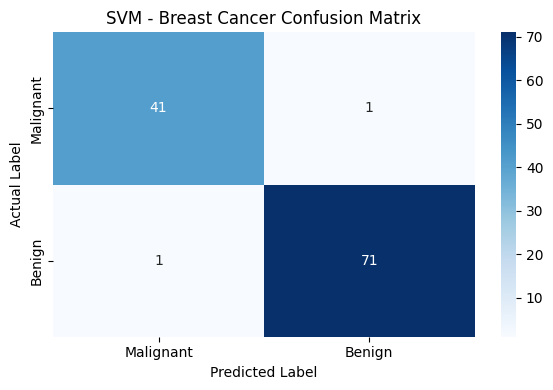

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_svm, labels=[0, 1])

# Print confusion matrix
print("SVM Confusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM - Breast Cancer Confusion Matrix")
plt.tight_layout()
plt.show()